# Tema 4 - Laboratorul 5: Rețele Markov

# Exercițiul 1: De la independență condiționată la factorizare
Avem graful $A - B - C$ și presupunem că $P(a,b,c) > 0$ pentru orice $a, b, c$.

## a) Ce înseamnă $A \perp C \mid B$
Înseamnă că, dacă știm deja valoarea lui $B$, să aflăm și valoarea lui $C$ nu ne mai spune nimic nou despre $A$:
$$P(a \mid b, c) = P(a \mid b), \quad \text{echivalent cu} \quad P(a, c \mid b) = P(a \mid b)\, P(c \mid b)$$

În graf, singurul drum de la $A$ la $C$ trece prin $B$. Dacă știm $B$, drumul e practic „blocat”, deci $C$ nu aduce informație suplimentară despre $A$. Dacă nu știm $B$, $A$ și $C$ pot fi dependente, pentru că $C$ spune ceva despre $B$, iar $B$ spune ceva despre $A$.

## b) $A \perp C \mid B \Rightarrow$ factorizare
Pornim de la regula produsului (definiția probabilității condiționate):
$$P(a,b,c) = P(a, c \mid b)\, P(b)$$

Din ipoteză, $P(a, c \mid b) = P(a \mid b)\, P(c \mid b)$, deci:
$$P(a,b,c) = P(a \mid b)\, P(c \mid b)\, P(b)$$

Folosim din nou regula produsului, $P(a \mid b)\,P(b) = P(a, b)$:
$$P(a,b,c) = P(a,b) \cdot P(c \mid b)$$

Așa că putem alege:
$$\phi_{AB}(a,b) = P(a,b), \qquad \phi_{BC}(b,c) = P(c \mid b), \qquad Z = 1$$

Potențialele sunt strict pozitive: $P(a,b) > 0$ și $P(c \mid b) = \frac{P(b,c)}{P(b)} > 0$, pentru că toate probabilitățile sunt pozitive (marginalele sunt sume de termeni pozitivi). Deci $P(a,b,c) = \frac{1}{Z}\phi_{AB}(a,b)\,\phi_{BC}(b,c)$. ∎

## c) Reciproca: factorizare $\Rightarrow A \perp C \mid B$
Presupunem că $P(a,b,c) = \frac{1}{Z}\phi_{AB}(a,b)\,\phi_{BC}(b,c)$, cu potențiale pozitive. Notăm:
$$\alpha(b) = \sum_a \phi_{AB}(a,b), \qquad \beta(b) = \sum_c \phi_{BC}(b,c)$$

**Marginala lui $B$.** Însumăm după $a$ și $c$. Primul factor nu depinde de $c$, iar al doilea nu depinde de $a$, deci suma se desparte:
$$P(b) = \frac{1}{Z}\Big(\sum_a \phi_{AB}(a,b)\Big)\Big(\sum_c \phi_{BC}(b,c)\Big) = \frac{1}{Z}\,\alpha(b)\,\beta(b)$$

**Probabilitatea condiționată.** Împărțim la $P(b)$, iar $Z$ se simplifică:
$$P(a, c \mid b) = \frac{P(a,b,c)}{P(b)} = \frac{\phi_{AB}(a,b)}{\alpha(b)} \cdot \frac{\phi_{BC}(b,c)}{\beta(b)}$$

**Marginalele condiționate.** Însumăm după $c$, respectiv după $a$ (fracția însumată dă 1):
$$P(a \mid b) = \sum_c P(a,c \mid b) = \frac{\phi_{AB}(a,b)}{\alpha(b)}, \qquad P(c \mid b) = \sum_a P(a,c \mid b) = \frac{\phi_{BC}(b,c)}{\beta(b)}$$

**Comparăm.** Rezultă $P(a, c \mid b) = P(a \mid b)\, P(c \mid b)$ pentru orice $a, b, c$, adică $A \perp C \mid B$. ∎

Pe scurt, pentru o distribuție strict pozitivă, independența condiționată și factorizarea pe clicile $\{A,B\}$ și $\{B,C\}$ sunt echivalente. E cazul cel mai simplu din teorema Hammersley–Clifford.

# Exercițiul 2: Putem prezice vremea la o stație fără observații?
## Datele alese
- 5 stații ($S_1, \dots, S_5$), fiecare cu stările Soare, Ploaie, Nori.
- Muchiile: $S_1 - S_2$, $S_1 - S_3$, $S_2 - S_4$, $S_2 - S_5$.
- Aceleași probabilități inițiale la toate stațiile: $p = (0.5,\ 0.3,\ 0.2)$ pentru Soare, Ploaie, Nori.
- Potențialul pereche din enunț:
$$\Psi = \begin{pmatrix} 0.7 & 0.2 & 0.1 \\ 0.2 & 0.6 & 0.2 \\ 0.1 & 0.3 & 0.6 \end{pmatrix}$$

Pe diagonală sunt cele mai mari valori, deci două stații vecine „preferă” să aibă aceeași vreme. $\Psi$ nu e o matrice de probabilități condiționate, ci doar niște ponderi.

In [1]:
# bibliotecile folosite pt ex. 2 și 3
import warnings
warnings.filterwarnings('ignore')

import os
# calea către Graphviz pe Windows (pyAgrum îl folosește la desen)
os.environ["PATH"] += os.pathsep + r"C:\Program Files\Graphviz\bin"

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import pyagrum as gum
import pyagrum.lib.notebook as gnb

In [2]:
stari = ['Soare', 'Ploaie', 'Nori']
statii = ['S1', 'S2', 'S3', 'S4', 'S5']
muchii = [('S1', 'S2'), ('S1', 'S3'), ('S2', 'S4'), ('S2', 'S5')]

p = [0.5, 0.3, 0.2]
Psi = np.array([[0.7, 0.2, 0.1],
                [0.2, 0.6, 0.2],
                [0.1, 0.3, 0.6]])

## a) Graful și vecinii

vecinii lui S1: ['S2', 'S3']
vecinii lui S2: ['S1', 'S4', 'S5']
vecinii lui S3: ['S1']
vecinii lui S4: ['S2']
vecinii lui S5: ['S2']

E arbore (fără cicluri)? True
muchii: 4  noduri: 5


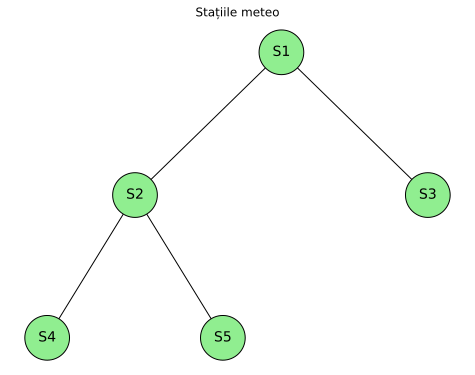

In [3]:
graf = nx.Graph(muchii)

for s in statii:
    print(f"vecinii lui {s}: {sorted(graf.neighbors(s))}")

print("\nE arbore (fără cicluri)?", nx.is_tree(graf))
print("muchii:", graf.number_of_edges(), " noduri:", graf.number_of_nodes())

pozitii = {'S1': (0, 2), 'S2': (-1, 1), 'S3': (1, 1), 'S4': (-1.6, 0), 'S5': (-0.4, 0)}
nx.draw(graf, pozitii, with_labels=True, node_size=2000, node_color='lightgreen',
        edgecolors='black', font_size=14)
plt.title('Stațiile meteo')
plt.show()

### Explicații:
`nx.is_tree` verifică dacă graful e conex și nu are cicluri. Se vede și din numărul de muchii: un arbore cu 5 noduri are exact 4 muchii. $S_3$, $S_4$ și $S_5$ au câte un singur vecin.

## b) Modelul în pyAgrum
Pentru fiecare stație punem un factor unar $\phi_i(s) = p(s)$. Pentru fiecare muchie punem un factor pereche $\phi_{ij}(s_i, s_j) = \Psi_{s_i, s_j}$, cu ordinea $(S_i, S_j)$ din lista de muchii.

In [4]:
mrf = gum.MarkovRandomField('Vreme')
for s in statii:
    mrf.add(gum.LabelizedVariable(s, s, stari))

# factorii unari
for s in statii:
    f = mrf.addFactor([s])
    f.fillWith(p)

# factorii pereche: prima stație din muchie = rândul din Psi, a doua = coloana
for i, j in muchii:
    f = mrf.addFactor([i, j])
    for a in range(3):
        for b in range(3):
            f[{i: a, j: b}] = Psi[a][b]

print(mrf.factor(['S1', 'S2']))


      ║  S1                         │
S2    ║Soare    │Ploaie   │Nori     │
──────║─────────│─────────│─────────│
Soare ║ 0.7000  │ 0.2000  │ 0.1000  │
Ploaie║ 0.2000  │ 0.6000  │ 0.3000  │
Nori  ║ 0.1000  │ 0.2000  │ 0.6000  │



### Explicații:
Factorul pereche l-am completat element cu element (`f[{i: a, j: b}] = Psi[a][b]`), ca să fiu sigur că ordinea e cea corectă. În afișarea pyAgrum, $S_1$ apare pe coloane și $S_2$ pe rânduri, deci tabelul apare transpus, dar valorile sunt cele din $\Psi$. De exemplu, la $S_1$ = Ploaie și $S_2$ = Nori avem $\Psi_{Ploaie, Nori} = 0.2$.

## c) Graful modelului și distribuția comună

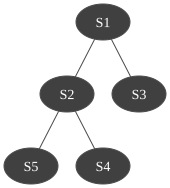

In [5]:
try:
    gnb.showMRF(mrf, view='graph')
except Exception:
    nx.draw(graf, pozitii, with_labels=True, node_size=2000, node_color='lightgreen',
            edgecolors='black', font_size=14)
    plt.show()

Distribuția comună este produsul tuturor factorilor, împărțit la $Z$:
$$P(s_1, \dots, s_5) = \frac{1}{Z} \prod_{i=1}^{5} \phi_i(s_i) \prod_{(i,j) \in E} \phi_{ij}(s_i, s_j)$$

Pentru graful nostru:
$$P(s_1, \dots, s_5) = \frac{1}{Z}\, p(s_1)\,p(s_2)\,p(s_3)\,p(s_4)\,p(s_5)\cdot \Psi_{s_1 s_2}\,\Psi_{s_1 s_3}\,\Psi_{s_2 s_4}\,\Psi_{s_2 s_5}$$

$Z$ e suma acestui produs peste toate cele $3^5 = 243$ de configurații. Fiind puține, le pot enumera.

In [6]:
def scor(config):
    # produsul factorilor pentru o configurație (stație -> indicele stării)
    rez = 1
    for s in statii:
        rez *= p[config[s]]
    for i, j in muchii:
        rez *= Psi[config[i]][config[j]]
    return rez

toate = [dict(zip(statii, c)) for c in itertools.product(range(3), repeat=5)]
Z = sum(scor(c) for c in toate)
print("configurații:", len(toate))
print(f"Z = {Z:.6f}")
print(f"P(peste tot Soare) = {scor({s: 0 for s in statii}) / Z:.4f}")

configurații: 243
Z = 0.020711
P(peste tot Soare) = 0.3623


## d) Marginalele la stațiile neobservate
Presupunem că știm vremea la două stații: $S_2$ = Ploaie și $S_4$ = Ploaie. Calculez $P(S_i \mid S_2 = \text{Ploaie}, S_4 = \text{Ploaie})$ pentru $S_1$, $S_3$ și $S_5$ cu inferența din pyAgrum (`ShaferShenoyMRFInference`). La fiecare stație, starea cu probabilitatea cea mai mare este MAP-ul marginal.

In [7]:
observatii = {'S2': 'Ploaie', 'S4': 'Ploaie'}
neobservate = [s for s in statii if s not in observatii]

inf = gum.ShaferShenoyMRFInference(mrf)
inf.setEvidence(observatii)
inf.makeInference()

map_marginal = {}
for s in neobservate:
    post = inf.posterior(s)
    val = [post[{s: k}] for k in range(3)]
    map_marginal[s] = stari[int(np.argmax(val))]
    print(f"{s}: Soare = {val[0]:.4f}, Ploaie = {val[1]:.4f}, Nori = {val[2]:.4f}  -> {map_marginal[s]}")

S1: Soare = 0.3701, Ploaie = 0.4957, Nori = 0.1343  -> Ploaie
S3: Soare = 0.4819, Ploaie = 0.3769, Nori = 0.1411  -> Soare
S5: Soare = 0.3125, Ploaie = 0.5625, Nori = 0.1250  -> Ploaie


In [8]:
# verific pentru S1 prin enumerare
obs_idx = {s: stari.index(v) for s, v in observatii.items()}
compatibile = [c for c in toate if all(c[s] == v for s, v in obs_idx.items())]
total = sum(scor(c) for c in compatibile)
for k in range(3):
    suma_k = sum(scor(c) for c in compatibile if c['S1'] == k)
    print(f"P(S1 = {stari[k]} | obs) = {suma_k / total:.4f}")

P(S1 = Soare | obs) = 0.3701
P(S1 = Ploaie | obs) = 0.4957
P(S1 = Nori | obs) = 0.1343


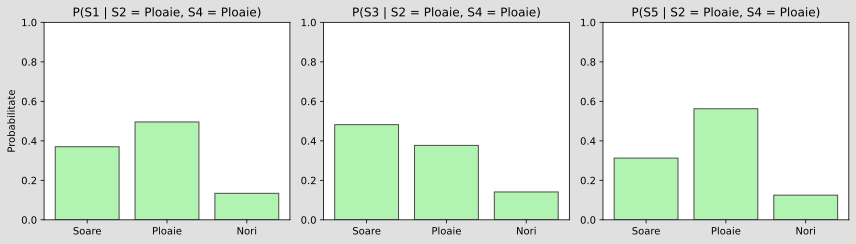

In [9]:
fig, axe = plt.subplots(1, len(neobservate), figsize=(12, 3.5))
for ax, s in zip(axe, neobservate):
    post = inf.posterior(s)
    ax.bar(stari, [post[{s: k}] for k in range(3)], alpha=0.7, color='lightgreen', edgecolor='black')
    ax.set_title(f'P({s} | S2 = Ploaie, S4 = Ploaie)')
    ax.set_ylim(0, 1)
axe[0].set_ylabel('Probabilitate')
plt.tight_layout()
plt.show()

### Interpretare:
- $S_5$ e vecin direct cu $S_2$, unde plouă, deci cel mai probabil plouă și acolo (0.56).
- La $S_1$ tot Ploaia iese cea mai probabilă (0.50), dar Soarele rămâne destul de aproape (0.37), din cauza lui $p(\text{Soare}) = 0.5$.
- $S_3$ nu are niciun vecin observat. Informația ajunge la el doar prin $S_1$, așa că la el câștigă Soarele (0.48).

Deci da, putem estima vremea și la stațiile fără observații: informația „circulă” prin muchii de la stațiile observate la vecini.

## e) MAP-ul comun
Acum caut o singură configurație $(s_1, s_3, s_5)$ care să fie cea mai probabilă împreună, știind observațiile:
$$(s_1, s_3, s_5)^* = \arg\max P(s_1, s_3, s_5 \mid S_2 = \text{Ploaie}, S_4 = \text{Ploaie})$$
Sunt doar $3^3 = 27$ de variante, așa că le iau pe toate.

In [10]:
def map_comun(observatii):
    obs_idx = {s: stari.index(v) for s, v in observatii.items()}
    neobs = [s for s in statii if s not in observatii]
    lista = []
    for valori in itertools.product(range(3), repeat=len(neobs)):
        config = dict(obs_idx)
        config.update(zip(neobs, valori))
        lista.append(({s: stari[config[s]] for s in neobs}, scor(config)))
    total = sum(sc for _, sc in lista)
    lista.sort(key=lambda t: t[1], reverse=True)
    return [(conf, sc / total) for conf, sc in lista]

rez = map_comun(observatii)
print("Primele 5 configurații:")
for conf, pr in rez[:5]:
    print(f"  {conf}  P = {pr:.4f}")

print("\nMAP comun:   ", rez[0][0])
print("MAP marginal:", map_marginal)
print("Coincid?", rez[0][0] == map_marginal)

Primele 5 configurații:
  {'S1': 'Soare', 'S3': 'Soare', 'S5': 'Ploaie'}  P = 0.1694
  {'S1': 'Ploaie', 'S3': 'Ploaie', 'S5': 'Ploaie'}  P = 0.1568
  {'S1': 'Soare', 'S3': 'Soare', 'S5': 'Soare'}  P = 0.0941
  {'S1': 'Ploaie', 'S3': 'Soare', 'S5': 'Ploaie'}  P = 0.0871
  {'S1': 'Ploaie', 'S3': 'Ploaie', 'S5': 'Soare'}  P = 0.0871

MAP comun:    {'S1': 'Soare', 'S3': 'Soare', 'S5': 'Ploaie'}
MAP marginal: {'S1': 'Ploaie', 'S3': 'Soare', 'S5': 'Ploaie'}
Coincid? False


### Interpretare:
Rezultatele diferă la $S_1$. Separat, $S_1$ = Ploaie e cea mai probabilă, dar împreună cea mai bună combinație e $S_1$ = Soare, $S_3$ = Soare, $S_5$ = Ploaie.

Motivul: perechea $(S_1, S_3)$ = (Soare, Soare) are potențialul 0.7, pe când (Ploaie, Soare) are doar 0.2. Probabilitatea marginală pentru $S_1$ = Ploaie e mare pentru că adună mai multe configurații, fiecare mai puțin probabilă. MAP-ul comun, în schimb, se uită la o singură configurație.

Cum spune și cursul, MAP e o problemă de optimizare globală, iar maximizarea fiecărei marginale separat nu dă în general aceeași configurație.

In [11]:
# alt caz: observăm doar S1 = Soare
obs2 = {'S1': 'Soare'}
inf2 = gum.ShaferShenoyMRFInference(mrf)
inf2.setEvidence(obs2)
inf2.makeInference()

marg2 = {}
for s in statii:
    if s not in obs2:
        post = inf2.posterior(s)
        marg2[s] = stari[int(np.argmax([post[{s: k}] for k in range(3)]))]

print("MAP comun:   ", map_comun(obs2)[0][0])
print("MAP marginal:", marg2)
print("Coincid?", map_comun(obs2)[0][0] == marg2)

MAP comun:    {'S2': 'Soare', 'S3': 'Soare', 'S4': 'Soare', 'S5': 'Soare'}
MAP marginal: {'S2': 'Soare', 'S3': 'Soare', 'S4': 'Soare', 'S5': 'Soare'}
Coincid? True


Aici ies la fel (Soare peste tot). Deci uneori coincid, dar nu întotdeauna.

# Exercițiul 3: Restaurarea unei imagini binare
## a) Imaginea originală
Am ales o imagine 5×5 cu un pătrat alb de 3×3 în mijloc, pe fond negru.

[[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]


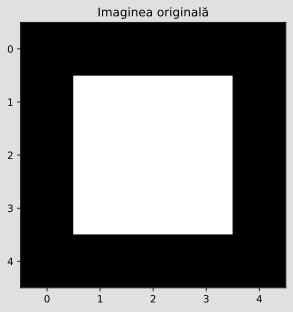

In [12]:
np.random.seed(6)

original = np.zeros((5, 5), dtype=int)
original[1:4, 1:4] = 1

print(original)
plt.imshow(original, cmap='gray', vmin=0, vmax=1)
plt.title('Imaginea originală')
plt.show()

## b) Imaginea cu zgomot
Fiecare pixel e inversat cu probabilitatea 0.1, deci în medie cam 10% dintre pixeli.

pixeli inversați: 2
[[0 0 0 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [1 0 0 0 0]]


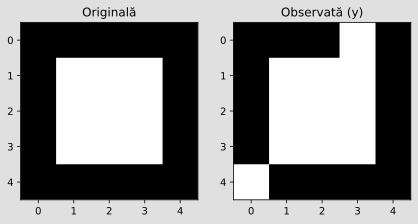

In [13]:
zgomot = np.random.rand(5, 5) < 0.1
y = original.copy()
y[zgomot] = 1 - y[zgomot]

print("pixeli inversați:", zgomot.sum())
print(y)

fig, axe = plt.subplots(1, 2, figsize=(7, 3.5))
axe[0].imshow(original, cmap='gray', vmin=0, vmax=1); axe[0].set_title('Originală')
axe[1].imshow(y, cmap='gray', vmin=0, vmax=1);        axe[1].set_title('Observată (y)')
plt.show()

## c) Modelul și energia
Fiecare pixel $x_i$ e o variabilă 0/1, legată de vecinii de sus, jos, stânga și dreapta. Energia este:
$$E(x; y) = \lambda \sum_i (x_i - y_i)^2 + \sum_{(i,j) \in E} (x_i - x_j)^2$$

- Primul termen măsoară cât de diferită e imaginea reconstruită de cea observată. Pentru pixeli 0/1, $(x_i - y_i)^2$ e 1 dacă pixelul a fost schimbat și 0 altfel.
- Al doilea termen numără perechile de vecini cu culori diferite, deci favorizează zonele uniforme (netezirea).
- $\lambda$ decide care dintre cele două contează mai mult.

Din $P(x \mid y) \propto e^{-E(x;y)}$ și din faptul că exponențiala unei sume e produsul exponențialelor, obținem potențialele:
$$\phi_i(x_i) = e^{-\lambda (x_i - y_i)^2}, \qquad \phi_{ij}(x_i, x_j) = e^{-(x_i - x_j)^2}$$

Energie mică înseamnă probabilitate mare, deci MAP-ul e imaginea cu energia minimă.

In [14]:
def nume(r, c):
    return f"x{r}{c}"

def vecini(r, c):
    v = []
    for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        if 0 <= r + dr < 5 and 0 <= c + dc < 5:
            v.append((r + dr, c + dc))
    return v

# muchiile grilei, fiecare o singură dată (spre dreapta și în jos)
muchii_grila = []
for r in range(5):
    for c in range(5):
        if c + 1 < 5: muchii_grila.append(((r, c), (r, c + 1)))
        if r + 1 < 5: muchii_grila.append(((r, c), (r + 1, c)))
print("muchii:", len(muchii_grila))

def energie(x, y, lam):
    return lam * np.sum((x - y) ** 2) + sum((x[a] - x[b]) ** 2 for a, b in muchii_grila)

muchii: 40


## d) Factorii în pyAgrum și MAP cu ICM

variabile: 25  factori: 65

  x00              │
0        │1        │
─────────│─────────│
 1.0000  │ 0.3679  │



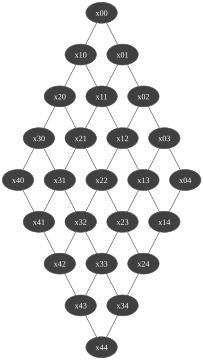

In [15]:
def construieste_mrf(y, lam):
    mrf = gum.MarkovRandomField('Imagine')
    for r in range(5):
        for c in range(5):
            mrf.add(gum.LabelizedVariable(nume(r, c), nume(r, c), 2))

    # factori unari: valoarea pentru x = 0 și pentru x = 1
    for r in range(5):
        for c in range(5):
            f = mrf.addFactor([nume(r, c)])
            f.fillWith([np.exp(-lam * (0 - y[r, c]) ** 2),
                        np.exp(-lam * (1 - y[r, c]) ** 2)])

    # factori pereche: 1 dacă vecinii sunt egali, e^-1 dacă sunt diferiți
    for a, b in muchii_grila:
        f = mrf.addFactor([nume(*a), nume(*b)])
        f.fillWith([1, np.exp(-1), np.exp(-1), 1])
    return mrf

mrf_img = construieste_mrf(y, lam=1)
print("variabile:", mrf_img.size(), " factori:", len(mrf_img.factors()))
print(mrf_img.factor([nume(0, 0)]))

try:
    gnb.showMRF(mrf_img, view='graph')
except Exception:
    print("Graphviz nu e instalat, nu pot desena graful.")

### ICM
Grila are $2^{25}$ (aproape 33 de milioane) de configurații, deci nu le-am încercat pe toate. Am folosit ICM, metoda din curs:
1. Pornesc de la imaginea observată ($x = y$).
2. Iau pe rând fiecare pixel.
3. Îi dau valoarea (0 sau 1) pentru care energia e mai mică, cu ceilalți pixeli ținuți fixați. Contează doar termenii care conțin pixelul respectiv:
$$E_i(v) = \lambda (v - y_i)^2 + \sum_{j \in N(i)} (v - x_j)^2$$
4. Repet până nu se mai schimbă niciun pixel.

E rapid, dar se poate opri într-un minim local, deci nu garantează MAP-ul global.

In [16]:
def icm(y, lam):
    x = y.copy()
    schimbat = True
    while schimbat:
        schimbat = False
        for r in range(5):
            for c in range(5):
                energii = []
                for v in [0, 1]:
                    e = lam * (v - y[r, c]) ** 2
                    for rr, cc in vecini(r, c):
                        e += (v - x[rr, cc]) ** 2
                    energii.append(e)
                best = int(np.argmin(energii))
                if energii[best] < energii[x[r, c]]:   # schimb doar dacă scade energia
                    x[r, c] = best
                    schimbat = True
    return x

x_map = icm(y, lam=1)
print(x_map)
print("energia lui y:      ", energie(y, y, 1))
print("energia după ICM:   ", energie(x_map, y, 1))
print("pixeli greșiți:     ", np.sum(x_map != original))

[[0 0 0 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]
energia lui y:       15
energia după ICM:    14
pixeli greșiți:      1


In [17]:
# verific că produsul factorilor din pyAgrum este e^(-E)
def produs_factori(mrf, x):
    prod = 1
    for r in range(5):
        for c in range(5):
            prod *= mrf.factor([nume(r, c)])[{nume(r, c): int(x[r, c])}]
    for a, b in muchii_grila:
        prod *= mrf.factor([nume(*a), nume(*b)])[{nume(*a): int(x[a]), nume(*b): int(x[b])}]
    return prod

print(f"produs factori: {produs_factori(mrf_img, x_map):.4e}")
print(f"e^(-E):         {np.exp(-energie(x_map, y, 1)):.4e}")

produs factori: 8.3153e-07
e^(-E):         8.3153e-07


### Explicații:
La fiecare pixel compar două valori: energia dacă pixelul e negru și energia dacă e alb, și o păstrez pe cea mai mică. De exemplu, un pixel alb izolat pe fond negru costă $\lambda$ dacă îl fac negru și numărul de vecini dacă îl las alb. Deci dacă $\lambda$ e mai mic decât numărul de vecini, ICM îl corectează.

Produsul factorilor din pyAgrum iese egal cu $e^{-E}$, deci când minimizez energia de fapt maximizez $P(x \mid y)$.

## e) Mai multe valori pentru $\lambda$

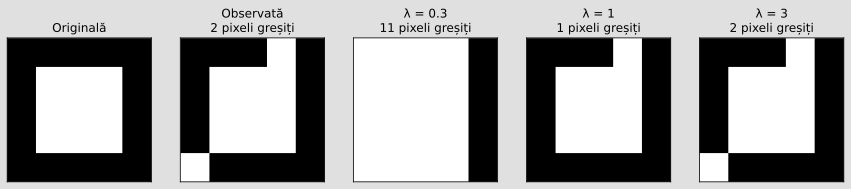

,lambda,pixeli greșiți,E(ICM),E(tot negru)
0,0.3,11,7.7,3.3
1,1.0,1,14.0,11.0
2,3.0,2,15.0,33.0


In [18]:
valori_lambda = [0.3, 1, 3]

fig, axe = plt.subplots(1, 2 + len(valori_lambda), figsize=(15, 3.5))
axe[0].imshow(original, cmap='gray', vmin=0, vmax=1); axe[0].set_title('Originală')
axe[1].imshow(y, cmap='gray', vmin=0, vmax=1)
axe[1].set_title(f'Observată\n{np.sum(y != original)} pixeli greșiți')

tabel = []
for ax, lam in zip(axe[2:], valori_lambda):
    x_rec = icm(y, lam)
    gresiti = np.sum(x_rec != original)
    tabel.append({'lambda': lam, 'pixeli greșiți': gresiti,
                  'E(ICM)': energie(x_rec, y, lam),
                  'E(tot negru)': energie(np.zeros((5, 5), dtype=int), y, lam)})
    ax.imshow(x_rec, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'λ = {lam}\n{gresiti} pixeli greșiți')
for ax in axe:
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

pd.DataFrame(tabel)

### Interpretare:
- Cu $\lambda = 0.3$, netezirea contează mult mai mult decât observația, așa că pixelii își copiază vecinii aproape fără să țină cont de $y$. Imaginea se umple de alb și iese cea mai greșită (11 pixeli).
- Cu $\lambda = 1$, rezultatul e cel mai bun: zgomotul din colț dispare și pătratul rămâne. Doar pixelul de zgomot lipit de pătrat rămâne greșit.
- Cu $\lambda = 3$, observația contează cel mai mult, așa că rezultatul e practic imaginea cu zgomot (2 pixeli greșiți).

Un $\lambda$ mic favorizează netezirea pentru că atunci costă puțin să nu respecți observația, deci domină termenul care vrea vecini egali. Un $\lambda$ mare face ca fiecare pixel schimbat să coste mult, așa că imaginea rămâne aproape de $y$, cu tot cu zgomot.

Totuși, pentru $\lambda = 0.3$ și $\lambda = 1$, imaginea complet neagră are energie mai mică decât ce a găsit ICM. Asta înseamnă că ICM s-a oprit într-un minim local, nu în MAP-ul global. Pentru $\lambda$ mic, MAP-ul global ar șterge chiar tot pătratul, pentru că marginea lui are 12 perechi alb–negru, care costă mai mult decât $9\lambda$. La $\lambda = 3$, imaginea neagră are energia 33, deci nu mai e avantajoasă.